In [1]:
# importing needed packages
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
path = 'D:\\GHCN files'

In [5]:
cols = ['Station_name', 'DATE', 'precipitation']

dfs = {}
for filename in os.listdir(path):
    if filename.endswith(".psv"):
        full_path = os.path.join(path, filename)
        if filename.startswith("._"):
            continue

        try:
            dfs[filename] = pd.read_csv(
            full_path, sep='|', usecols=cols, low_memory=False, encoding='utf-8'
            )
        except UnicodeDecodeError:
            dfs[filename] = pd.read_csv(
            full_path, sep='|', usecols=cols, low_memory=False, encoding='cp1252'
            )
        print(f"{filename}: {dfs[filename].shape}")


GHCNh_USW00023155_por.psv: (981526, 3)
GHCNh_USW00093216_por.psv: (687629, 3)
GHCNh_USW00023203_por.psv: (687737, 3)
GHCNh_USW00093203_por.psv: (473664, 3)
GHCNh_USW00023254_por.psv: (496520, 3)
GHCNh_USW00023167_por.psv: (315783, 3)
GHCNh_USW00093193_por.psv: (867287, 3)
GHCNh_USW00023110_por.psv: (684213, 3)
GHCNh_USW00023285_por.psv: (460148, 3)
GHCNh_USW00093205_por.psv: (518905, 3)
GHCNh_USW00023257_por.psv: (393033, 3)
GHCNh_USW00023258_por.psv: (488230, 3)
GHCNh_USW00093227_por.psv: (484811, 3)
GHCNh_USW00024216_por.psv: (838197, 3)
GHCNh_USW00024257_por.psv: (573751, 3)
GHCNh_USW00023271_por.psv: (60704, 3)
GHCNh_USW00023232_por.psv: (946610, 3)
GHCNh_USW00023206_por.psv: (781906, 3)
GHCNh_USW00023208_por.psv: (911950, 3)
GHCNh_USW00093225_por.psv: (481267, 3)
GHCNh_USW00023237_por.psv: (805800, 3)
GHCNh_USW00000479_por.psv: (439768, 3)
GHCNh_USW00023202_por.psv: (883401, 3)
GHCNh_USW00093144_por.psv: (630457, 3)


In [ ]:
precip = pd.concat(dfs.values()).dropna(subset=['precipitation']).copy()
precip['DATE'] = pd.to_datetime(precip['DATE'])
precip['precipitation'] = pd.to_numeric(precip['precipitation'], errors='coerce')
precip = precip.dropna(subset=['precipitation'])


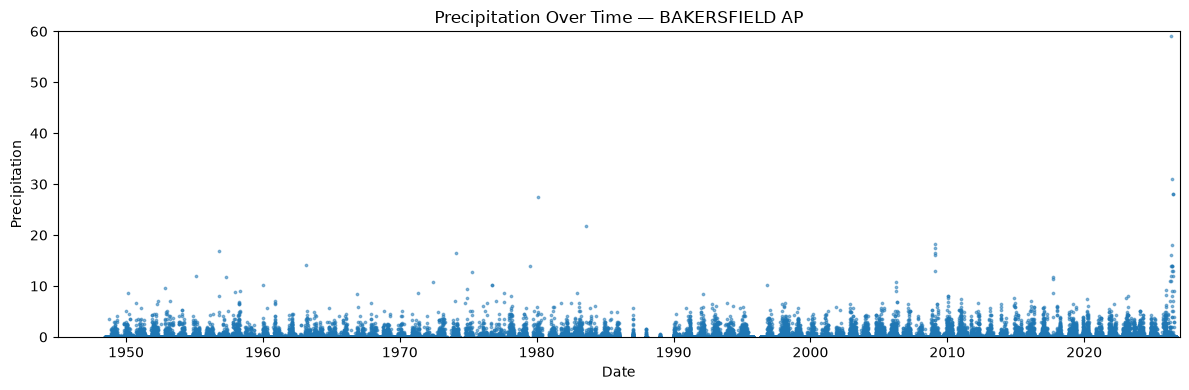

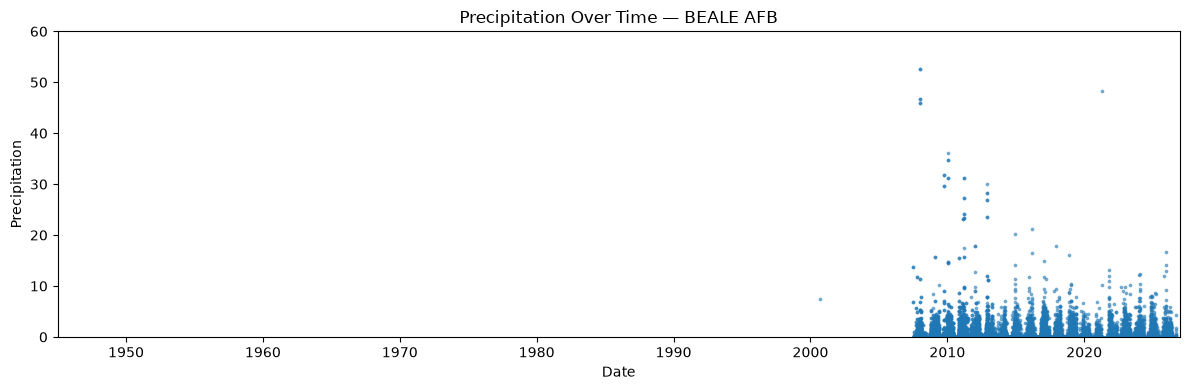

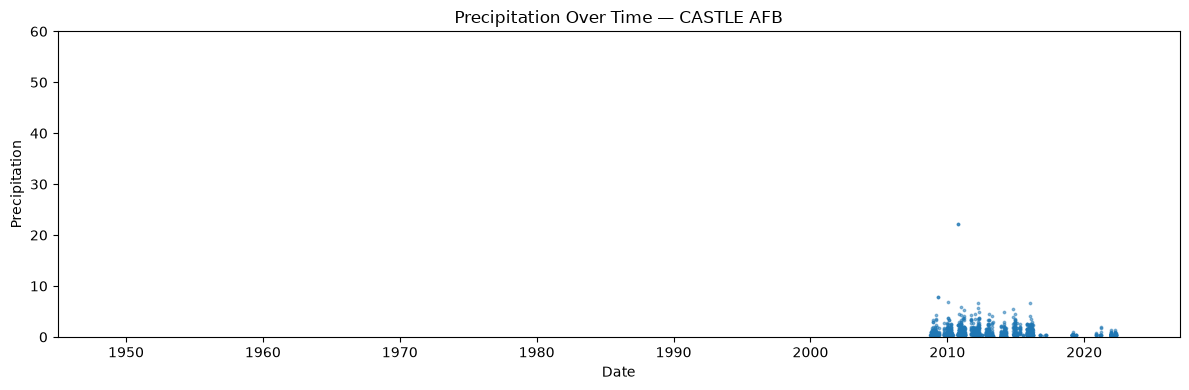

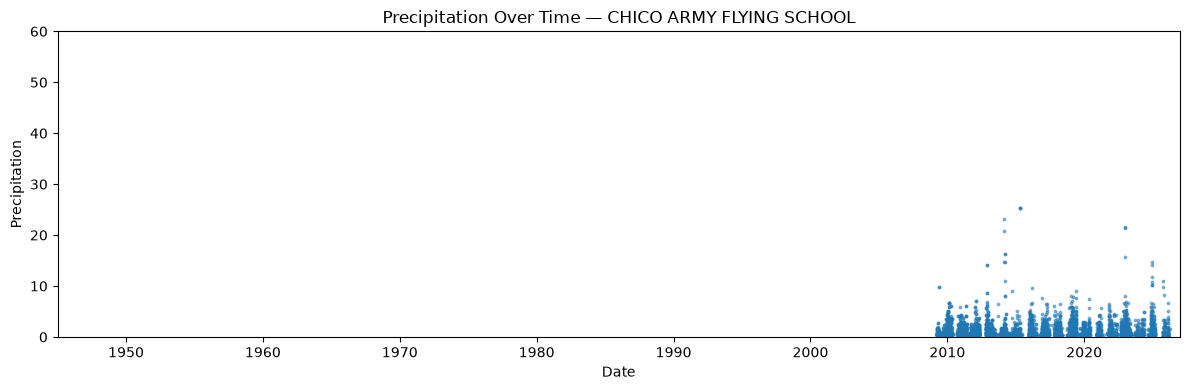

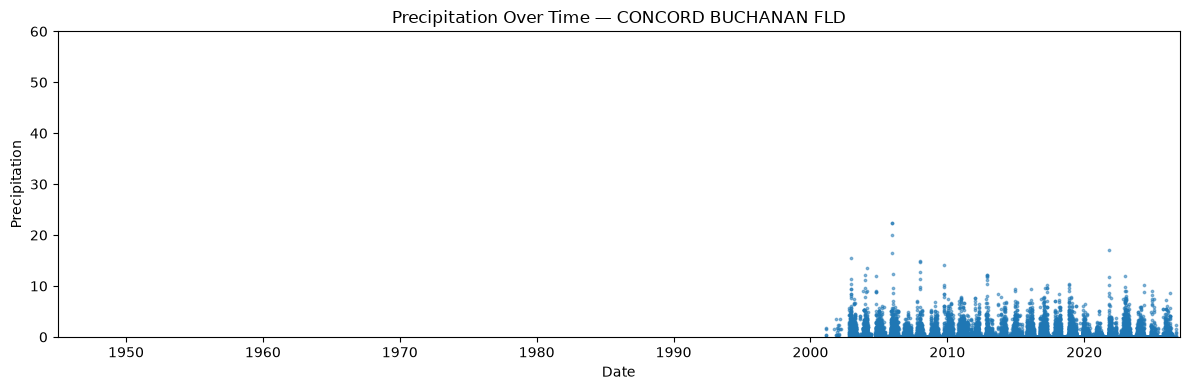

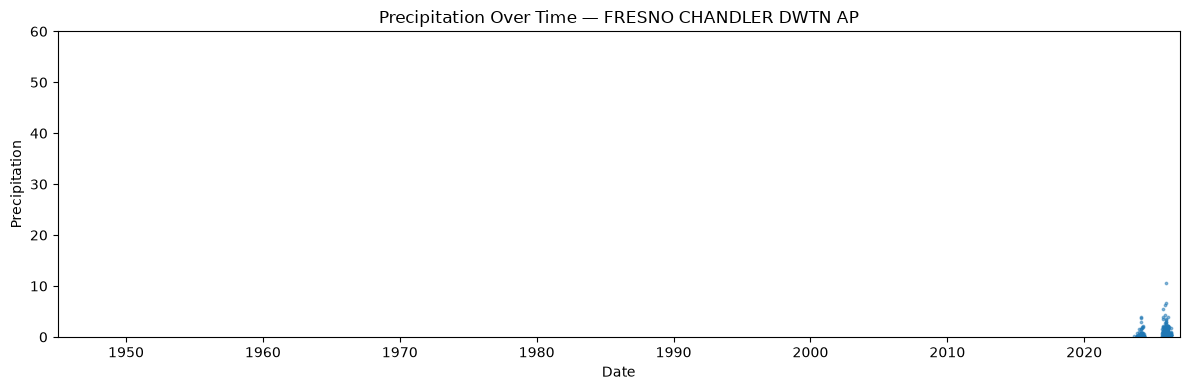

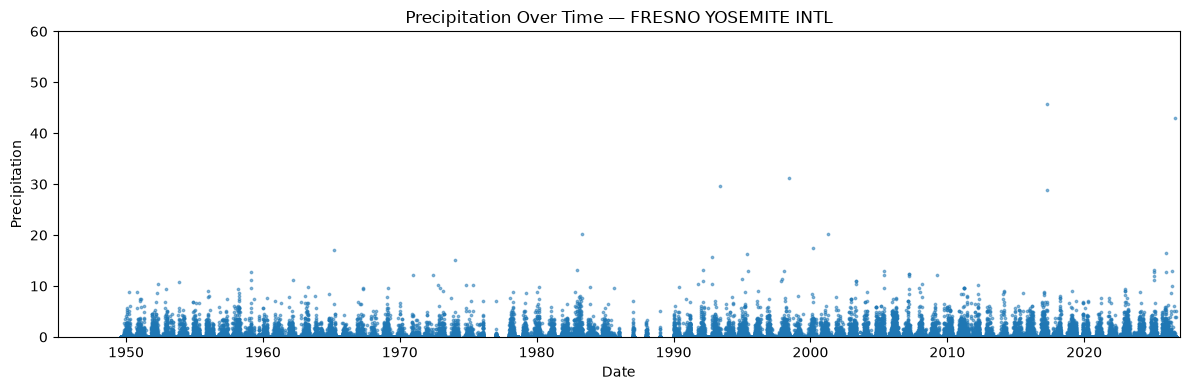

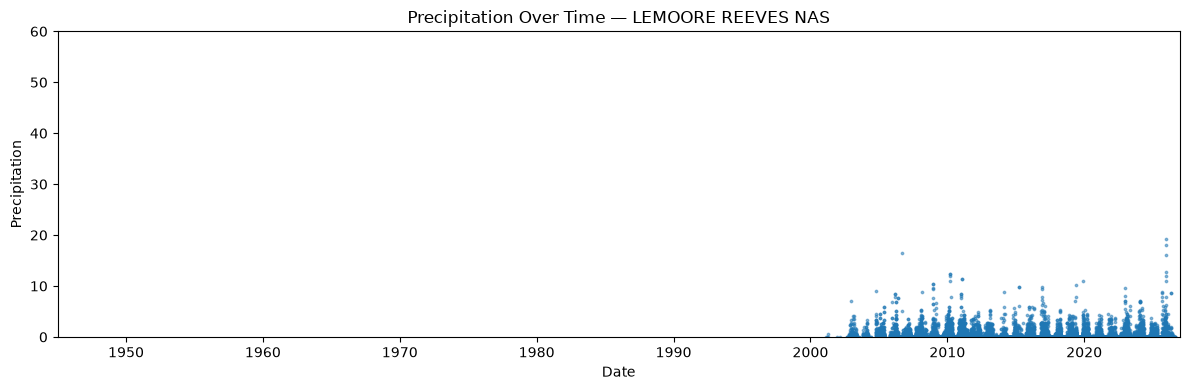

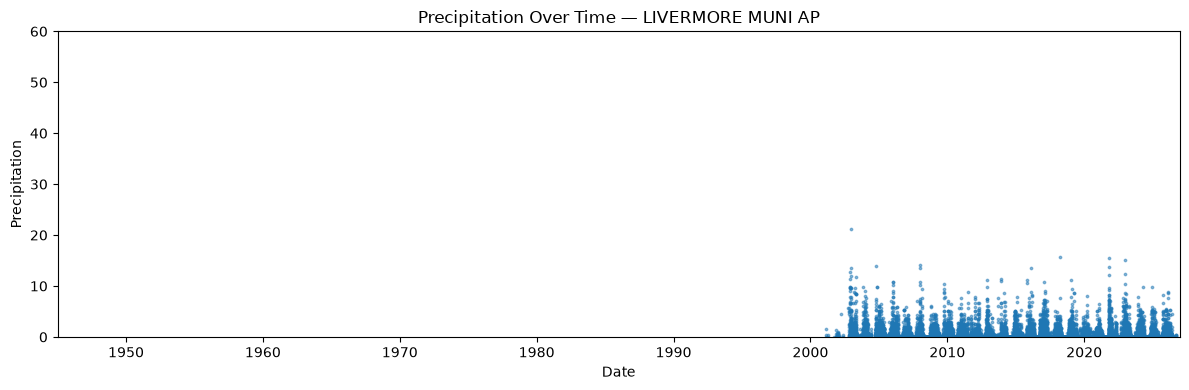

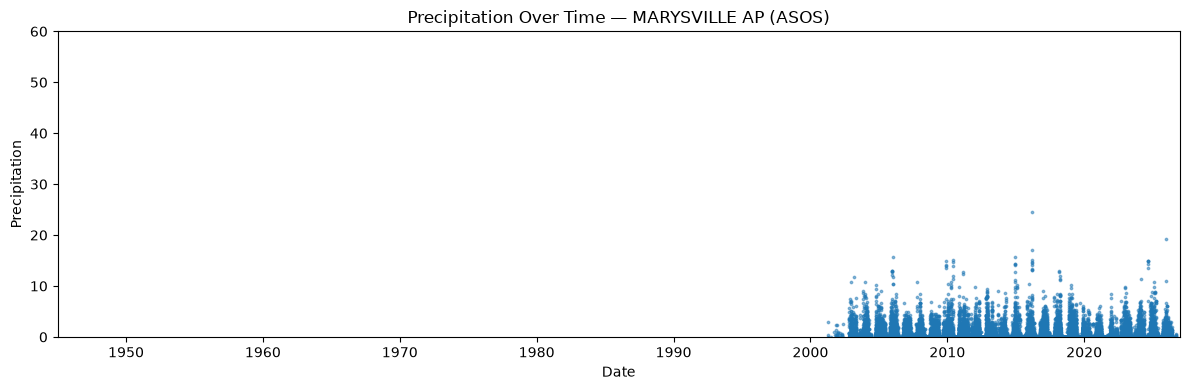

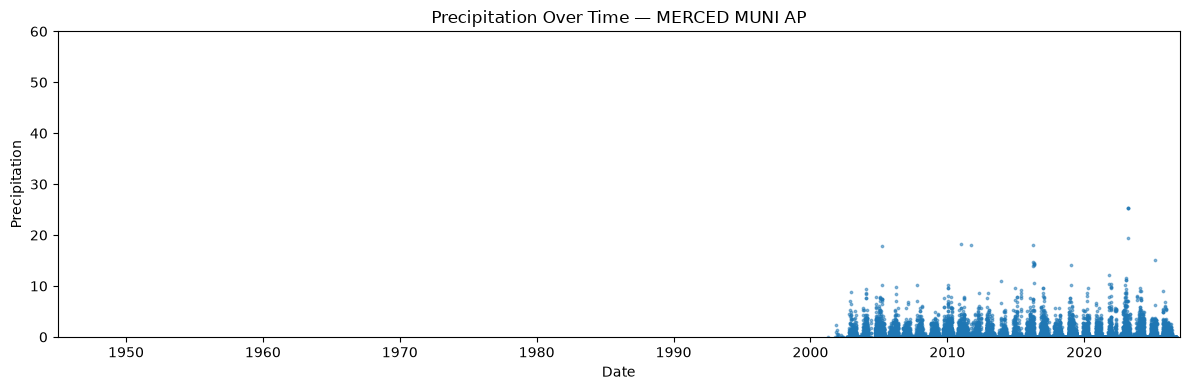

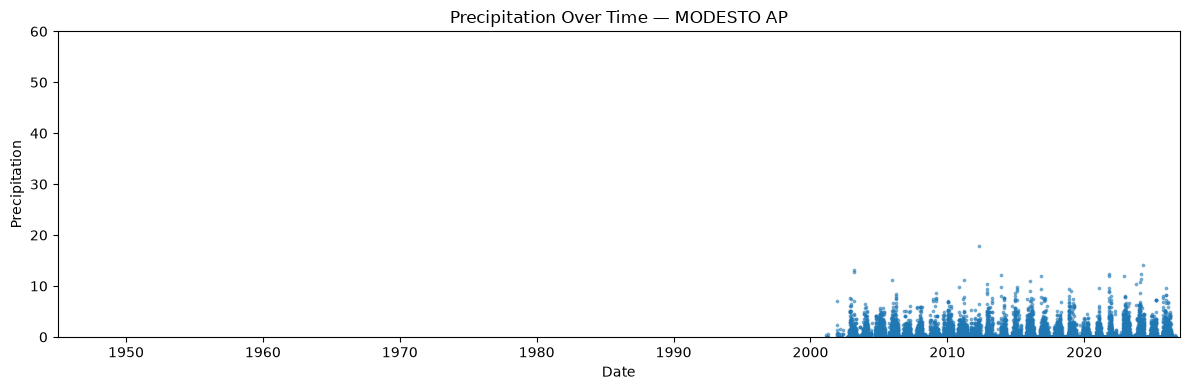

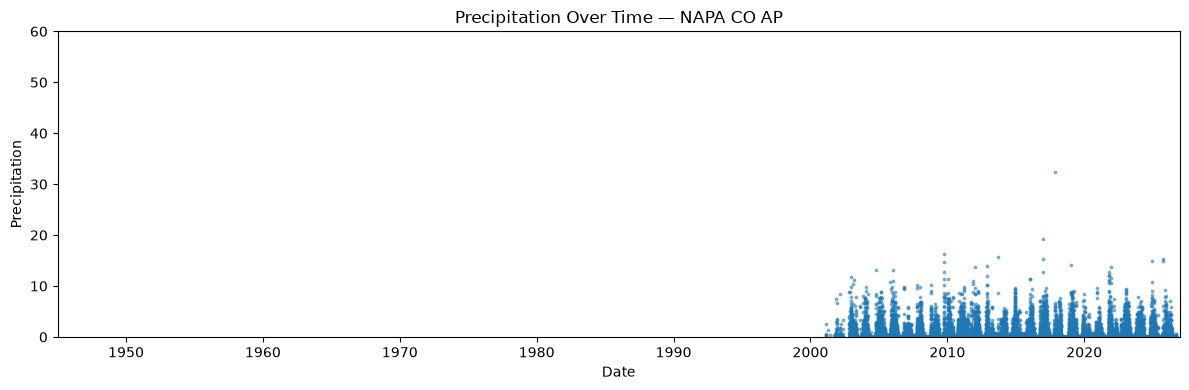

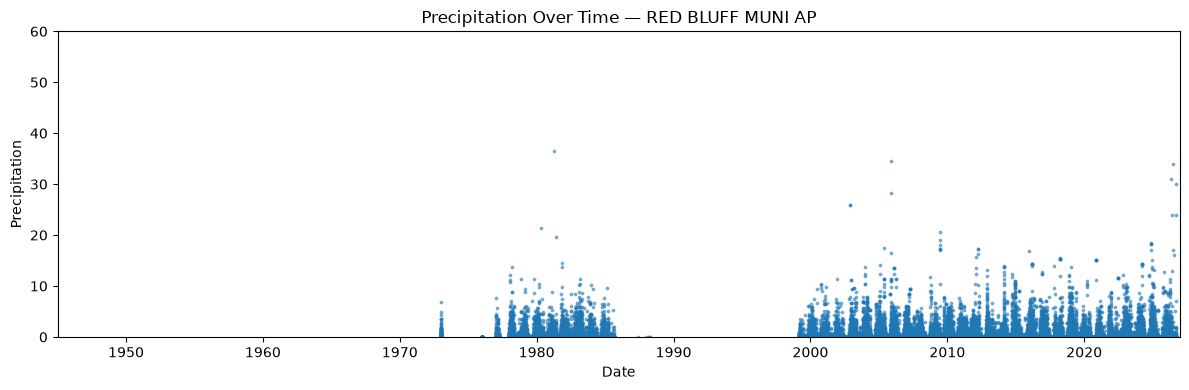

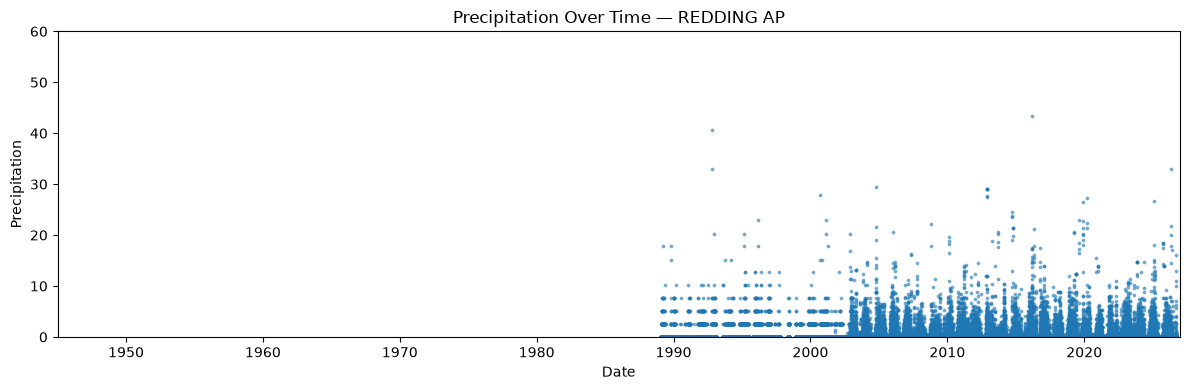

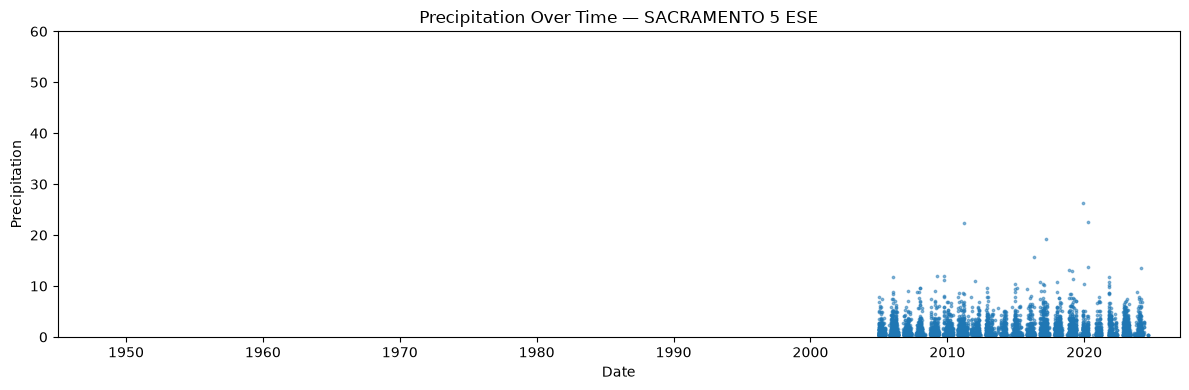

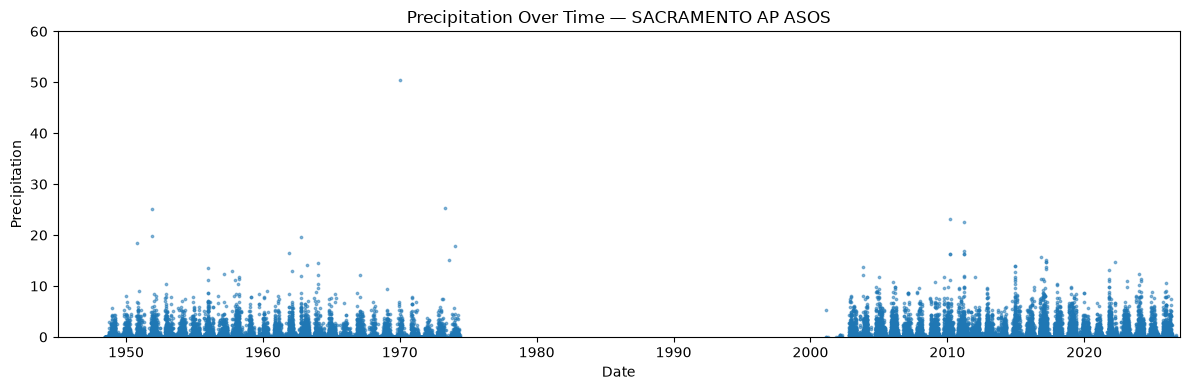

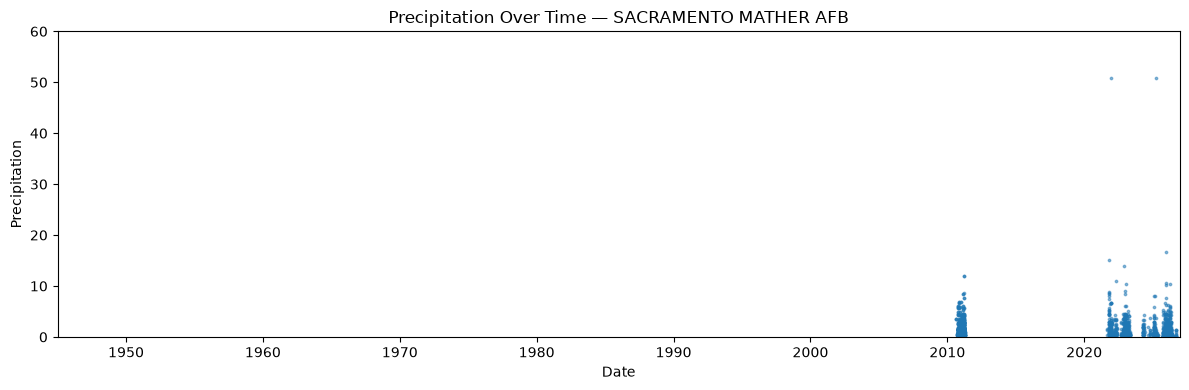

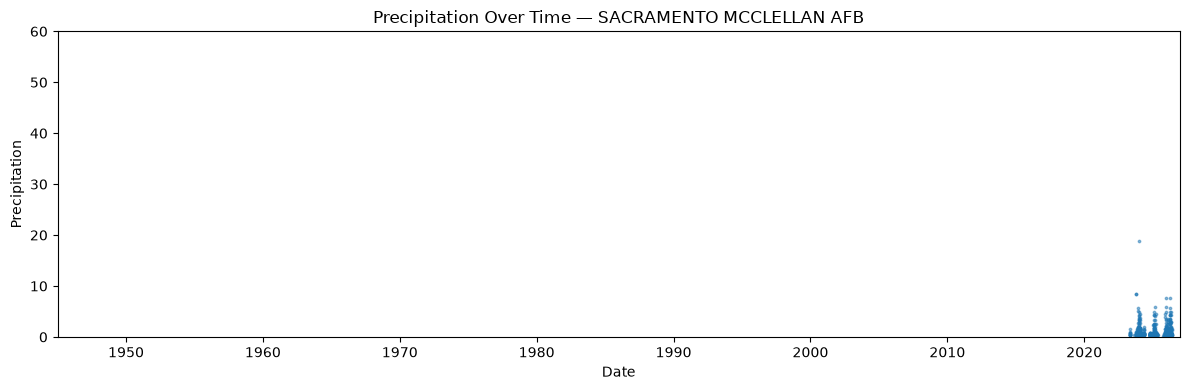

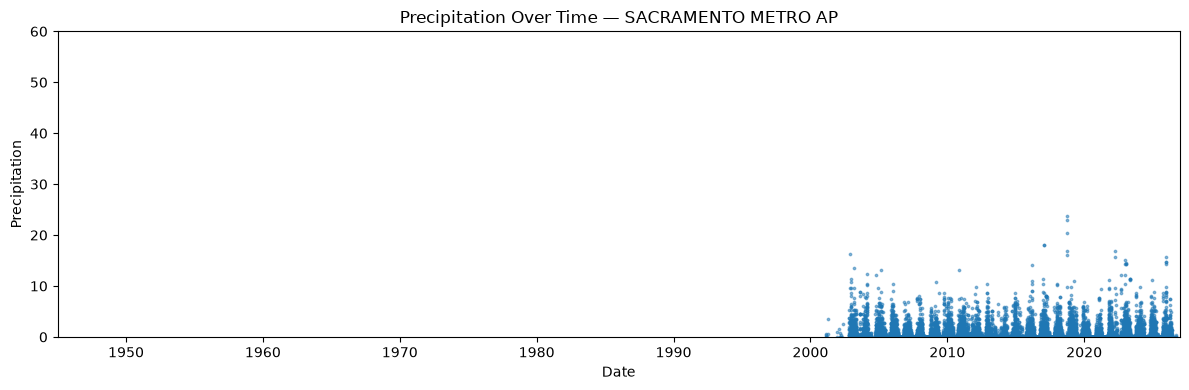

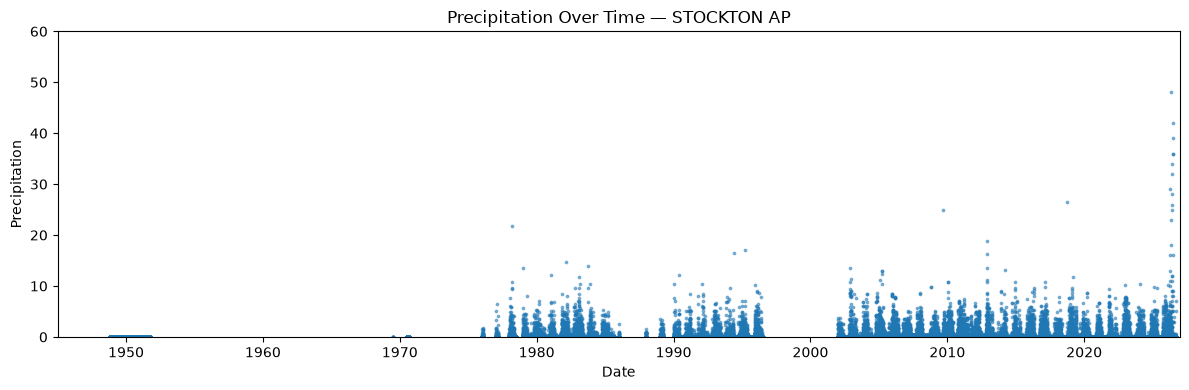

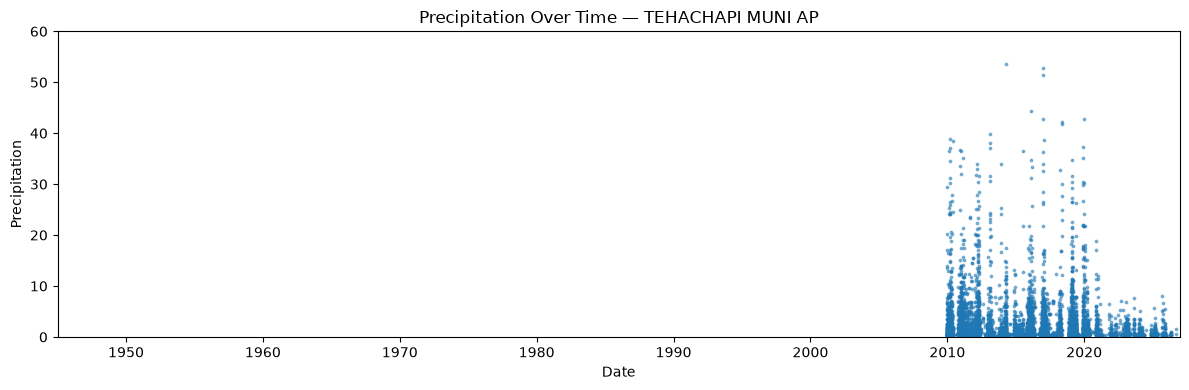

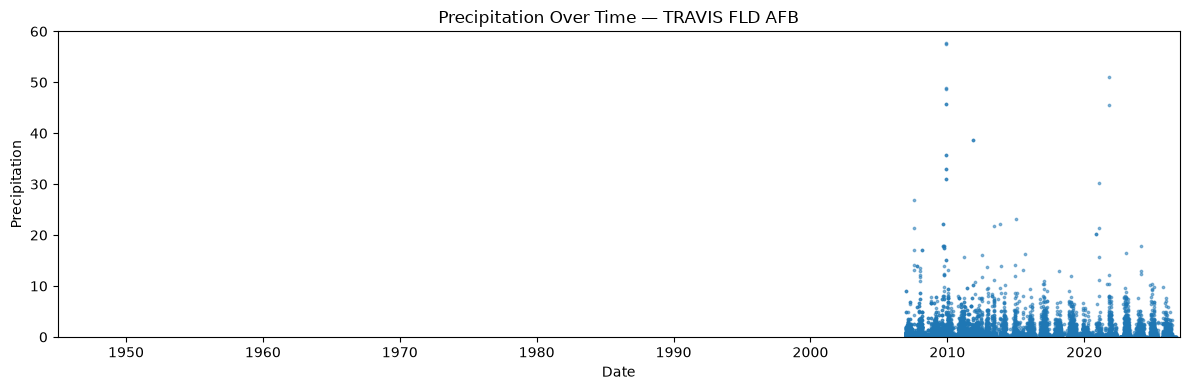

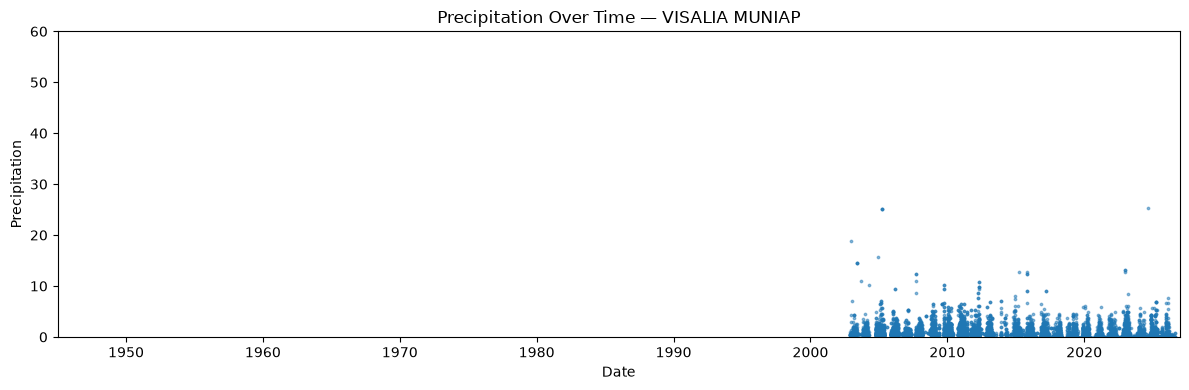

In [10]:
for station, data in precip.groupby('Station_name', sort=True):
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.scatter(data['DATE'], data['precipitation'], s=3, alpha=0.5, rasterized=True)
    ax.set(title=f'Precipitation Over Time — {station}',
           xlabel='Date', ylabel='Precipitation')
    # set x axis limits from the years 1945-2026
    ax.set_xlim(pd.Timestamp('1945-01-01'), pd.Timestamp('2026-12-31'))
    ax.set_ylim(0, 60)
    fig.tight_layout()
    plt.show()

In [11]:
for station in sorted(precip['Station_name'].dropna().unique()):
    print(station)

BAKERSFIELD AP
BEALE AFB
CASTLE AFB
CHICO ARMY FLYING SCHOOL
CONCORD BUCHANAN FLD
FRESNO CHANDLER DWTN AP
FRESNO YOSEMITE INTL
LEMOORE REEVES NAS
LIVERMORE MUNI AP
MARYSVILLE AP (ASOS)
MERCED MUNI AP
MODESTO AP
NAPA CO AP
RED BLUFF MUNI AP
REDDING AP
SACRAMENTO 5 ESE
SACRAMENTO AP ASOS
SACRAMENTO MATHER AFB
SACRAMENTO MCCLELLAN AFB
SACRAMENTO METRO AP
STOCKTON AP
TEHACHAPI MUNI AP
TRAVIS FLD AFB
VISALIA MUNIAP
